<a href="https://colab.research.google.com/github/Gunjannn07/FlyRank1/blob/main/work/notebooks/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Gunjannn07/FlyRank1/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

The project investigates whether safe search visibility, content, and engagement signals can identify content that may deserve CTR or engagement review.

The practical decision is **which content should be reviewed first**. A useful output is a ranked queue with an opportunity score, transparent reason codes, and a suggested action.

This project does **not** attempt to discover Google's ranking algorithm or prove that a content refresh causes better performance.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*


- **Starting dataset:** `data/raw/content_refresh_anonymized.csv`
- **Previously inspected warehouse table:** `fact_content_daily_performance`
- **Previously inspected date window:** 2026-03-01 to 2026-03-31
- **W03 warehouse scale:** 78,835,655 total rows; 9,841,378 rows for March 2026.
- **March data availability :** 3,611,061 rows with GSC data and 413,966 rows with GA4 data.
- **Previously used features/fields:** `search_volume`, `content_type`, `ctr`, `avg_position`, `engagement_rate`, `scroll_rate`, `ai_traffic_pct`, `position_tier`, `trend_direction`, `trend_pct`, `impression_tier`, and `char_count_tier`.


For the public paper, I excluded client names, domains, URLs, private queries, credentials, and raw identifying exports. Use anonymized identifiers only when permitted by the dataset rules.

> **Which data the results use:** every result in this notebook comes from the 30,000-row starter slice (`content_refresh_anonymized.csv`, 32 pseudonymized clients), not the 78M-row warehouse. The warehouse numbers above are context only.


In [1]:

import os
import sys
import subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/flyrank-bih/flyrank-ml-internship-starter"
REPO_DIR = "flyrank-ml-internship-starter"

if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(
            ["git", "clone", "--depth", "1", REPO_URL, REPO_DIR],
            check=True
        )

    os.chdir(REPO_DIR)

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"],
        check=True
    )

import pandas as pd
import numpy as np

df = pd.read_csv("data/raw/content_refresh_anonymized.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (30000, 44)


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9
3,content_331d6c4de07b,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,commercial,NaN,NaN,...,NaN,0.49,6.2,1.28,3.45,0.0,good,page_1,stable,-13.8
4,content_d99b7a2d90ca,client_3fdba35f04,0.0,0.00,LOW,0.00,keyword article,informational,2803.0,17469.0,...,15000-25000,0.13,44.0,0.00,24.29,0.0,good,page_3_5,down,-34.7


In [2]:
if "df" in globals():
    print("Columns:")
    print(df.columns.tolist())
    print("\nMissing values (top 20):")
    display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing_count"))
    print("\nDuplicate rows:", int(df.duplicated().sum()))
    for col in ["content_id", "client_id"]:
        if col in df.columns:
            print(f"Unique {col}:", df[col].nunique(dropna=True))

Columns:
['content_id', 'client_id', 'search_volume', 'competition', 'competition_level', 'cpc', 'content_type', 'main_intent', 'word_count', 'char_count', 'provider_used', 'model_used', 'impressions_90d', 'clicks_90d', 'pageviews_90d', 'sessions_90d', 'users_90d', 'engaged_sessions_90d', 'ai_sessions_90d', 'scroll_events_90d', 'days_with_impressions', 'days_with_sessions', 'impressions_last_30d', 'clicks_last_30d', 'sessions_last_30d', 'impressions_prev_30d', 'clicks_prev_30d', 'sessions_prev_30d', 'content_age_days', 'age_tier', 'age_tier_order', 'days_since_last_update', 'freshness_tier', 'word_count_tier', 'char_count_tier', 'ctr', 'avg_position', 'engagement_rate', 'scroll_rate', 'ai_traffic_pct', 'impression_tier', 'position_tier', 'trend_direction', 'trend_pct']

Missing values (top 20):


,missing_count
provider_used,21438
word_count,7699
char_count,7699
word_count_tier,7699
char_count_tier,7699
model_used,5733
trend_pct,3388
competition_level,2610
search_volume,2468
cpc,2468



Duplicate rows: 0
Unique content_id: 30000
Unique client_id: 32


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*


##### This capstone uses a **CTR / Engagement Opportunity Scoring** approach to identify content that may benefit from further review.

1. **Feature Engineering:** Use available search visibility, average position, CTR, content type, and engagement signals to characterize content performance.
2. **Opportunity Scoring:** Compare observed CTR with expected CTR for comparable position groups and consider search visibility to prioritize potential opportunities.
3. **Model Evaluation:** Compare a baseline with a Decision Tree model, using the same evaluation metric and held-out data. This notebook evaluates on client-grouped splits (`GroupShuffleSplit` by `client_id`, seed 42, plus 5-fold `GroupKFold`), so no client appears in both train and test. Pages with fewer than 500 impressions or no position data (`avg_position == 0`) are excluded. Banned features: `ctr`-derived columns, clicks, `trend_direction`, `trend_pct`, and IDs.
4. **Decision Support:** Generate a ranked content-review queue with reason codes and suggested actions to help prioritize editorial effort.

The scores indicate **review priorities, not guaranteed CTR improvements**. Results are observational and do not establish causal effects or reveal Google's ranking algorithm.

In [3]:
# Audit the target and available features before fitting anything.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

assert "df" in globals(), "Run the data-loading cell first."
assert "ctr" in df.columns, "The dataset must contain the target column 'ctr'."

target = "ctr"
numeric_candidates = [
    "search_volume", "avg_position", "competition", "cpc",
    "word_count", "char_count"
]
categorical_candidates = ["content_type", "main_intent"]

numeric_features = [c for c in numeric_candidates if c in df.columns]
categorical_features = [c for c in categorical_candidates if c in df.columns]
feature_cols = numeric_features + categorical_features

audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
}).sort_values("missing_pct", ascending=False)

print("Rows, columns:", df.shape)
print("Candidate numeric features:", numeric_features)
print("Candidate categorical features:", categorical_features)
display(audit)

df[target] = pd.to_numeric(df[target], errors="coerce")
print("\nCTR summary:")
display(df[target].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame("ctr"))
print("CTR values below zero:", int((df[target] < 0).sum()))
print("CTR values above 1:", int((df[target] > 1).sum()))
print("Note: ctr is already a percentage (0.76 means 0.76%), so values above 1 are ordinary CTRs above 1%.")


Rows, columns: (30000, 44)
Candidate numeric features: ['search_volume', 'avg_position', 'competition', 'cpc', 'word_count', 'char_count']
Candidate categorical features: ['content_type', 'main_intent']


,dtype,missing_count,missing_pct,unique_values
provider_used,object,21438,71.46,2
word_count,float64,7699,25.66,5476
char_count,float64,7699,25.66,14839
word_count_tier,object,7699,25.66,4
char_count_tier,object,7699,25.66,4
model_used,object,5733,19.11,5
trend_pct,float64,3388,11.29,2712
competition_level,object,2610,8.70,3
search_volume,float64,2468,8.23,41
cpc,float64,2468,8.23,915



CTR summary:


,ctr
count,30000.000000
mean,0.510733
std,3.279162
min,0.000000
1%,0.000000
5%,0.000000
25%,0.000000
50%,0.070000
75%,0.290000
95%,1.090000


CTR values below zero: 0
CTR values above 1: 1689
Note: ctr is already a percentage (0.76 means 0.76%), so values above 1 are ordinary CTRs above 1%.


In [4]:
# Inspecting the largest CTR values and their associated clicks
cols_to_check = [
    "ctr",
    "impressions_90d",
    "clicks_90d",
    "impressions_last_30d",
    "clicks_last_30d",
    "avg_position",
    "search_volume"
]

display(
    df[cols_to_check]
    .sort_values("ctr", ascending=False)
    .head(15)
)

,ctr,impressions_90d,clicks_90d,impressions_last_30d,clicks_last_30d,avg_position,search_volume
22607,100.00,1,1,0,0,1.0,NaN
19598,100.00,1,1,0,0,9.0,NaN
4606,100.00,1,1,0,0,1.0,0.0
7514,100.00,1,1,0,0,0.0,NaN
13661,100.00,1,1,0,0,2.0,NaN
25755,100.00,1,1,0,0,2.0,0.0
6473,100.00,1,1,1,1,25.0,NaN
240,100.00,1,1,0,0,1.0,0.0
19341,100.00,1,1,0,0,8.0,0.0
18825,100.00,1,1,0,0,1.0,NaN


### Exploratory analysis of CTR by avg. position

In [5]:
MIN_IMPR = 500   # volume floor: ignore pages with fewer than 500 impressions in 90 days
elig = df[(df["impressions_90d"] >= MIN_IMPR) & (df["avg_position"] > 0)].copy().reset_index(drop=True)
print("Pages kept:", len(elig), "of", len(df), "| clients:", elig["client_id"].nunique())
print("Rows with avg_position == 0 (no position data):", int((df["avg_position"] == 0).sum()))

order = ["1-3", "4-10", "11-20", "21+"]
elig["position_group"] = pd.cut(elig["avg_position"], bins=[0, 3, 10, 20, np.inf], labels=order).astype(str)

tbl = elig.groupby("position_group").agg(
    pages=("ctr", "size"),
    median_impressions=("impressions_90d", "median"),
    median_ctr=("ctr", "median"),
    clicks=("clicks_90d", "sum"),
    impressions=("impressions_90d", "sum"),
).loc[order]
tbl["weighted_ctr_pct"] = (tbl["clicks"] / tbl["impressions"] * 100).round(3)
display(tbl[["pages", "median_impressions", "median_ctr", "weighted_ctr_pct"]])


Pages kept: 16726 of 30000 | clients: 28
Rows with avg_position == 0 (no position data): 1205


,pages,median_impressions,median_ctr,weighted_ctr_pct
position_group,,,,
1-3,480,4382.5,0.20,0.489
4-10,7084,4502.0,0.24,0.348
11-20,4459,2166.0,0.17,0.351
21+,4703,2217.0,0.08,0.150


**Reading the table.** CTR falls as position gets worse (about 0.49% in positions 1-3 down to 0.15% at 21+), but positions 4-10 and 11-20 are almost identical (0.348% vs 0.351% impression-weighted), so position alone is a weak signal in this slice. The 1-3 median (0.20) is below the 4-10 median (0.24); that group has only 480 pages, so tier medians there are noisy and should not be over-read. Overall CTR in this slice is low, and top-3 CTR is far below the warehouse figure in the data dictionary, so these values should not be generalized.

## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*



In [6]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import spearmanr

SEED = 42
num_feats = ["avg_position", "search_volume", "competition", "cpc", "word_count", "char_count"]
cat_feats = ["content_type", "main_intent"]
banned = ["ctr", "clicks_90d", "clicks_last_30d", "clicks_prev_30d",
          "trend_direction", "trend_pct", "content_id", "client_id"]
assert not set(num_feats + cat_feats) & set(banned), "Leakage: a banned column is in the features!"

X = elig[num_feats + cat_feats + ["position_group"]]
y = elig["ctr"]
groups = elig["client_id"]

def make_tree():
    pre = ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=True), num_feats),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="unknown")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_feats),
    ])
    return Pipeline([("pre", pre),
                     ("tree", DecisionTreeRegressor(max_depth=4, min_samples_leaf=100, random_state=SEED))])

def score_models(tr, te):
    Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
    tier_median = ytr.groupby(Xtr["position_group"]).median()
    preds = {
        "baseline_1_global_median": np.full(len(yte), ytr.median()),
        "baseline_2_position_tier_median": Xte["position_group"].map(tier_median).fillna(ytr.median()).values,
        "decision_tree": make_tree().fit(Xtr, ytr).predict(Xte),
    }
    rows = []
    for name, p in preds.items():
        rho = spearmanr(yte, p)[0] if np.ptp(p) > 0 else np.nan
        rows.append({"model": name, "MAE": mean_absolute_error(yte, p),
                     "R2": r2_score(yte, p), "spearman": rho})
    return pd.DataFrame(rows)

tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X, y, groups))
print("Train clients:", groups.iloc[tr].nunique(), "| Test clients:", groups.iloc[te].nunique(),
      "| Clients in BOTH:", len(set(groups.iloc[tr]) & set(groups.iloc[te])))
print("Train pages:", len(tr), "| Test pages:", len(te))
single = score_models(tr, te)
print("\nSingle client-grouped split (same held-out clients for every model):")
display(single.round(4))

folds = pd.concat([score_models(a, b).assign(fold=i)
                   for i, (a, b) in enumerate(GroupKFold(n_splits=5).split(X, y, groups))])
cv = folds.groupby("model")[["MAE", "R2", "spearman"]].agg(["mean", "std"]).round(4)
print("\n5-fold client-grouped cross-validation (mean and std across folds):")
display(cv)


Train clients: 22 | Test clients: 6 | Clients in BOTH: 0
Train pages: 15466 | Test pages: 1260

Single client-grouped split (same held-out clients for every model):


,model,MAE,R2,spearman
0,baseline_1_global_median,0.2609,-0.1124,NaN
1,baseline_2_position_tier_median,0.2517,-0.0683,0.3385
2,decision_tree,0.2514,0.0705,0.3692



5-fold client-grouped cross-validation (mean and std across folds):


MAE              R2         spearman  \
                                   mean     std    mean     std     mean   
model                                                                      
baseline_1_global_median         0.2019  0.0323 -0.0945  0.0517      NaN   
baseline_2_position_tier_median  0.1949  0.0293 -0.0355  0.0691   0.3544   
decision_tree                    0.2088  0.0151  0.0257  0.0921   0.3658   

                                         
                                    std  
model                                    
baseline_1_global_median            NaN  
baseline_2_position_tier_median  0.0395  
decision_tree                    0.0516

In [7]:
fit_model = make_tree().fit(X.iloc[tr], y.iloc[tr])
names = fit_model.named_steps["pre"].get_feature_names_out()
imp = pd.Series(fit_model.named_steps["tree"].feature_importances_, index=names).sort_values(ascending=False)
display(imp.head(6).round(3).to_frame("importance"))


,importance
num__avg_position,0.801
num__missingindicator_char_count,0.123
num__search_volume,0.054
num__word_count,0.021
num__missingindicator_word_count,0.002
num__competition,0.000


**Results vs baseline (same held-out clients, same metric: MAE in CTR percentage points; the lower the better).**

| Model | Single split MAE | 5-fold MAE (mean ± std) | 5-fold Spearman |
|---|---|---|---|
| Baseline 1: global median | 0.2609 | 0.2019 ± 0.0323 | n/a (constant guess cannot rank) |
| Baseline 2: position-tier median | 0.2517 | 0.1949 ± 0.0293 | 0.354 |
| Decision Tree (depth 4) | 0.2514 | 0.2088 ± 0.0151 | 0.366 |

- Knowing the position tier helps a little over a single global guess.
- The Decision Tree ties the tier rule on the single split and is slightly worse on average MAE across folds. Its small gains in R² and Spearman are within fold-to-fold noise.
- R² values are near zero for every model: these features explain very little of page-to-page CTR variation.
- The tree mostly learned position (importance about 0.80). The 0.12 on a "char_count missing" flag reflects how data was collected (missingness follows content type), not content quality.
- **Conclusion:** a transparent position-adjusted rule is about as good as this model for prioritizing review, so the ranked queue below uses the simple rule.

## 5. Limitations

*What this work cannot claim.*

- **Observational only.** One 90-day slice (30,000 pages; 28 clients after filtering). Nothing here shows that rewriting a page improves CTR.
- **Low-CTR slice.** CTR is low overall and top-3 CTR is far below the warehouse figure in the data dictionary, so tier values should not be generalized.
- **Sensitivity to choices.** Results depend on the 500-impression floor and on the four position groups.
- **Approximate tiers.** `avg_position` is a 90-day average, so position tiers are approximate.
- **Systematic missingness.** Keyword and length fields are missing along content-type lines, so missingness can carry hidden information.
- **Low CTR has many causes.** Search-page changes, intent mismatch or AI answers can lower clicks, not only a weak title or meta description.
- **Concentration.** One client supplies about 56% of the top-100 queue.
- **Weak model signal.** The Decision Tree did not reliably beat a simple baseline, so model-based claims are not made.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

1. Review the top-ranked pages first: high impressions, positions 4-10, CTR far below the tier's typical CTR. The top 100 pages hold about 26% of all estimated missed clicks (top 500: 54%; top 1000: 68%).
2. For pages flagged `ctr_below_half_of_tier` and `page_one_position`, check the title/meta description and intent match.
3. For `weak_engagement` pages, review the on-page experience.
4. Pages with fewer than 10 sessions go to monitoring until there is more evidence.
5. Balance reviews across clients so one client does not dominate the queue.

**Evidence and limits.** "Missed clicks" means clicks relative to what a typical page at that position group gets; it is a prioritization number, not a forecast. In the persistence check, pages with a CTR gap in the older 30 days mostly keep it in the newer 30 days (Spearman about 0.60; about 83% of the worst 10% stay above the median gap), so the gaps are not just random noise. This is still observational and decision-support only. Reason-code thresholds are a first pass (for example, a high-ranked page can land on "monitor") and should be tuned with editors.

In [8]:
elig["expected_ctr"] = elig.groupby("position_group")["ctr"].transform("median")
elig["expected_clicks"] = elig["expected_ctr"] / 100 * elig["impressions_90d"]
elig["missed_clicks"] = (elig["expected_clicks"] - elig["clicks_90d"]).clip(lower=0)

# Relative cutoff: the starter's fixed "below 30" rule flags every page here (median engagement is ~2%).
eng_cut = elig.loc[elig["sessions_90d"] >= 30, "engagement_rate"].quantile(0.50)
print("Weak-engagement cutoff (lower half of pages with >=30 sessions):", round(float(eng_cut), 2))

def reason_codes(r):
    codes = []
    if r.impressions_90d >= 5000: codes.append("high_impressions")
    if r.ctr < 0.5 * r.expected_ctr: codes.append("ctr_below_half_of_tier")
    if r.avg_position <= 10: codes.append("page_one_position")
    if r.sessions_90d >= 30 and r.engagement_rate < eng_cut: codes.append("weak_engagement")
    if r.sessions_90d < 10: codes.append("low_session_evidence")
    return codes

def suggested_action(codes):
    if "low_session_evidence" in codes: return "monitor (too little session data)"
    if "weak_engagement" in codes: return "improve on-page engagement"
    if "page_one_position" in codes and "ctr_below_half_of_tier" in codes: return "review title/meta description"
    if "ctr_below_half_of_tier" in codes: return "review intent match / snippet"
    return "monitor"

elig["reason_codes"] = elig.apply(reason_codes, axis=1)
elig["suggested_action"] = elig["reason_codes"].apply(suggested_action)
queue = elig.sort_values("missed_clicks", ascending=False).reset_index(drop=True)
queue.insert(0, "rank", queue.index + 1)
queue["reason_codes"] = queue["reason_codes"].apply(lambda c: ", ".join(c))

show = ["rank", "content_id", "avg_position", "impressions_90d", "clicks_90d",
        "ctr", "expected_ctr", "missed_clicks", "suggested_action"]
display(queue[show].head(10).round(2))

total = queue["missed_clicks"].sum()
print("Share of all 'missed clicks' in the top 100 / 500 / 1000 pages:",
      [round(float(queue["missed_clicks"].head(k).sum() / total), 3) for k in (100, 500, 1000)])
top100 = queue.head(100)
print("Top-100: distinct clients =", top100["client_id"].nunique(),
      "| biggest client's share =", round(float(top100["client_id"].value_counts(normalize=True).iloc[0]), 2))
print(top100["suggested_action"].value_counts().to_dict())


Weak-engagement cutoff (lower half of pages with >=30 sessions): 1.96


,rank,content_id,avg_position,impressions_90d,clicks_90d,ctr,expected_ctr,missed_clicks,suggested_action
0,1,content_36ff89c8214e,7.3,295097,154,0.05,0.24,554.23,improve on-page engagement
1,2,content_5fe46e04994d,4.2,517715,741,0.14,0.24,501.52,monitor
2,3,content_c8e9d6ab9013,9.7,208678,0,0.00,0.24,500.83,monitor (too little session data)
3,4,content_8451fc6f034d,2.3,272144,75,0.03,0.20,469.29,review title/meta description
4,5,content_c84a0ab98e90,7.8,223271,70,0.03,0.24,465.85,review title/meta description
5,6,content_453722754fea,7.6,140079,16,0.01,0.24,320.19,monitor (too little session data)
6,7,content_73c54f78c06a,4.7,213963,211,0.10,0.24,302.51,improve on-page engagement
7,8,content_91652435f57a,7.8,159590,100,0.06,0.24,283.02,improve on-page engagement
8,9,content_c1fe78bc4e37,7.5,134055,43,0.03,0.24,278.73,improve on-page engagement
9,10,content_a7427266c305,5.7,201111,219,0.11,0.24,263.67,review title/meta description


Share of all 'missed clicks' in the top 100 / 500 / 1000 pages: [0.264, 0.543, 0.683]
Top-100: distinct clients = 13 | biggest client's share = 0.56
{'improve on-page engagement': 42, 'review title/meta description': 38, 'monitor': 12, 'monitor (too little session data)': 5, 'review intent match / snippet': 3}


In [9]:
# Does the gap persist? Gap measured in the older 30 days vs the newer 30 days (no label leakage).
p = df[(df["impressions_prev_30d"] >= 300) & (df["impressions_last_30d"] >= 300) & (df["avg_position"] > 0)].copy()
p["ctr_prev"] = p["clicks_prev_30d"] / p["impressions_prev_30d"] * 100
p["ctr_last"] = p["clicks_last_30d"] / p["impressions_last_30d"] * 100
p["grp"] = pd.cut(p["avg_position"], bins=[0, 3, 10, 20, np.inf], labels=order).astype(str)
p["gap_prev"] = p.groupby("grp")["ctr_prev"].transform("median") - p["ctr_prev"]
p["gap_last"] = p.groupby("grp")["ctr_last"].transform("median") - p["ctr_last"]
print("Pages:", len(p), "| Spearman (older gap vs newer gap):", round(float(spearmanr(p["gap_prev"], p["gap_last"])[0]), 3))
worst = p.nlargest(int(len(p) * 0.10), "gap_prev")
print("Of the worst 10% (older window), share still above-median gap in the newer window:",
      round(float((worst["gap_last"] > p["gap_last"].median()).mean()), 3))


Pages: 10944 | Spearman (older gap vs newer gap): 0.604
Of the worst 10% (older window), share still above-median gap in the newer window: 0.826


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

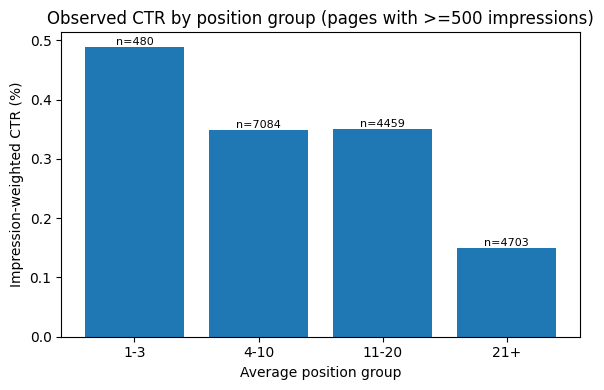

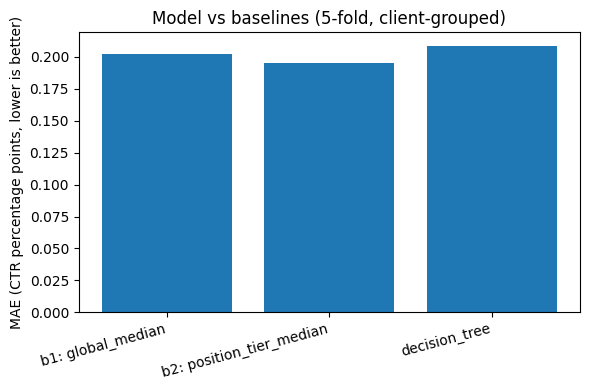

Saved: work/outputs/capstone_metrics.json, work/figures/ctr_by_position.png, work/figures/model_vs_baseline.png


,pages,median_impressions,median_ctr,weighted_ctr_pct
position_group,,,,
1-3,480,4382.5,0.20,0.489
4-10,7084,4502.0,0.24,0.348
11-20,4459,2166.0,0.17,0.351
21+,4703,2217.0,0.08,0.150


MAE              R2         spearman  \
                                   mean     std    mean     std     mean   
model                                                                      
baseline_1_global_median         0.2019  0.0323 -0.0945  0.0517      NaN   
baseline_2_position_tier_median  0.1949  0.0293 -0.0355  0.0691   0.3544   
decision_tree                    0.2088  0.0151  0.0257  0.0921   0.3658   

                                         
                                    std  
model                                    
baseline_1_global_median            NaN  
baseline_2_position_tier_median  0.0395  
decision_tree                    0.0516

,rank,content_id,avg_position,impressions_90d,clicks_90d,ctr,expected_ctr,missed_clicks,suggested_action
0,1,content_36ff89c8214e,7.3,295097,154,0.05,0.24,554.23,improve on-page engagement
1,2,content_5fe46e04994d,4.2,517715,741,0.14,0.24,501.52,monitor
2,3,content_c8e9d6ab9013,9.7,208678,0,0.00,0.24,500.83,monitor (too little session data)
3,4,content_8451fc6f034d,2.3,272144,75,0.03,0.20,469.29,review title/meta description
4,5,content_c84a0ab98e90,7.8,223271,70,0.03,0.24,465.85,review title/meta description
5,6,content_453722754fea,7.6,140079,16,0.01,0.24,320.19,monitor (too little session data)
6,7,content_73c54f78c06a,4.7,213963,211,0.10,0.24,302.51,improve on-page engagement
7,8,content_91652435f57a,7.8,159590,100,0.06,0.24,283.02,improve on-page engagement
8,9,content_c1fe78bc4e37,7.5,134055,43,0.03,0.24,278.73,improve on-page engagement
9,10,content_a7427266c305,5.7,201111,219,0.11,0.24,263.67,review title/meta description


In [10]:
import json
from pathlib import Path
Path("work/figures").mkdir(parents=True, exist_ok=True)
Path("work/outputs").mkdir(parents=True, exist_ok=True)

cv_flat = {m: {"MAE_mean": float(cv.loc[m, ("MAE", "mean")]), "MAE_std": float(cv.loc[m, ("MAE", "std")]),
               "R2_mean": float(cv.loc[m, ("R2", "mean")]), "spearman_mean": float(cv.loc[m, ("spearman", "mean")])}
           for m in cv.index}
metrics = {"seed": SEED, "min_impressions": MIN_IMPR, "pages_kept": int(len(elig)),
           "single_split": single.round(4).to_dict(orient="records"), "grouped_5fold": cv_flat}
Path("work/outputs/capstone_metrics.json").write_text(json.dumps(metrics, indent=2))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(tbl.index, tbl["weighted_ctr_pct"])
ax.set_xlabel("Average position group")
ax.set_ylabel("Impression-weighted CTR (%)")
ax.set_title("Observed CTR by position group (pages with >=500 impressions)")
for i, (n, v) in enumerate(zip(tbl["pages"], tbl["weighted_ctr_pct"])):
    ax.text(i, v, f"n={n}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.savefig("work/figures/ctr_by_position.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
mae = cv[("MAE", "mean")]
ax.bar([m.replace("baseline_1_", "b1: ").replace("baseline_2_", "b2: ") for m in mae.index], mae.values)
ax.set_ylabel("MAE (CTR percentage points, lower is better)")
ax.set_title("Model vs baselines (5-fold, client-grouped)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("work/figures/model_vs_baseline.png", dpi=150)
plt.show()

print("Saved: work/outputs/capstone_metrics.json, work/figures/ctr_by_position.png, work/figures/model_vs_baseline.png")
display(tbl[["pages", "median_impressions", "median_ctr", "weighted_ctr_pct"]])
display(cv)
display(queue[show].head(10).round(2))


## ML-12: Demo outline, social post, employer summary

### 5-minute demo outline
- **0:00 Problem:** many pages, limited editor time. Which ones should be reviewed first?
- **0:45 Data and cleaning:** 30k-page anonymized slice; fixed the "position 0 = no data" and tiny-page noise issues.
- **1:45 Method:** expected CTR by position group; baseline vs Decision Tree on client-grouped splits.
- **2:45 Result:** the tree ties the simple rule, so the simple rule is used.
- **3:30 Output:** the ranked queue with reason codes and suggested actions.
- **4:15 Limits and next steps:** observational only; one client dominates the queue; tune thresholds with editors.
- **4:45 Questions.**

### Social-post cut
Finished my FlyRank ML internship capstone. I ranked content for CTR review using position-adjusted expected CTR. A Decision Tree did not beat the simple baseline, and learning to report that honestly was the lesson. Decision-support only, no causal claims.

### Employer-facing summary (3 sentences)
I built a position-adjusted CTR opportunity score on an anonymized 30k-page dataset, with client-grouped validation and leakage checks. I found that a transparent baseline matched a Decision Tree, so I shipped the simpler, explainable ranked queue with reason codes. I also caught and fixed data issues (missing-position rows, low-volume noise) and documented the limits of the evidence.


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
